In [2]:
display("text/html", "<style>.container { width:100% !important; }</style>")

In [61]:
using DataFrames, CSV, Plots, LaTeXStrings, DelimitedFiles, GLM, BlackBoxOptim, Distances, Printf, Plots.Measures

In [4]:
Plots.theme(:dao)

In [5]:
include("/home/jamesh/GitHub/Ecological-Preferential-Attachment/diversity-simulator.jl")
using .dsim

In [6]:
pal = cgrad(:tol_muted);
cpal10 = [pal[i] for i in 0.0:1/46:1];

In [7]:
read_data = CSV.read("/home/jamesh/GitHub/Ecological-Preferential-Attachment/Data_csv/Grilli-crosssecdata__datatax.csv", DataFrame)
# first split on classification
gd1 = groupby(read_data, :classification);

For each classification, split up on the sample.

In [8]:
gd_classes = []
for gd in gd1
    push!(gd_classes, groupby(gd, :sample_id))
end

In [9]:
read_data = CSV.read("/home/jamesh/GitHub/Ecological-Preferential-Attachment/Data_csv/Grilli-crosssecdata__datatax.csv", DataFrame)
read_data = filter(:nreads => !=(0), read_data)
# first split on classification
gd1 = groupby(read_data, :classification);

gd_classes = []
for gd in gd1
    push!(gd_classes, groupby(gd, :sample_id))
end

classes = [gd_classes[i][1][!,:classification][2] for i in 1:length(gd_classes)]
classes = strip.(lowercase.(classes))
classes[10] = "marine hydrothermal vents"
classes[6] = "oral cavity"
classes[5] = "terrestrial soil"
classes[end] = "activated sludge"
classes

14-element Vector{SubString{String}}:
 "seawater"
 "oral"
 "gut"
 "vaginal"
 "terrestrial soil"
 "oral cavity"
 "feces"
 "skin"
 "glacier"
 "marine hydrothermal vents"
 "river"
 "lake"
 "environmental aquatic marine"
 "activated sludge"

In [40]:
cpal_plot =  [pal[i] for i in 0.0:1/11:1]

# Index 1

Index choice below specifies the index of system we are dealing with.

In [481]:
ind_choice = 1;

In [482]:
data = gd_classes[ind_choice];

We need to get the size of each of these systems.

In [483]:
sizes = sum.([data[x][!,:count] for x in 1:length(data)]);
maximum(sizes)

492477.0

In [484]:
small_to_large = sortperm(sizes);

In [485]:
ic_sys = sort(data[small_to_large[2]][!,:count],rev=true);

In [486]:
# need to find the bounding value of p0
logxs = log10.(sum.([x[!,:count] for x in data]));
logys = log10.(length.([x[!,:count] for x in data]));
df = DataFrame(y = logys, x = logxs);
glm = lm(@formula(y ~ x), df);
a,b = coef(glm);
θ = 2+1/(b-1);
α = sum([k^θ for k in ic_sys])/(sum(ic_sys)^(1/(2-θ)));
p0_guess = α*b*10^a

3.479563394700048

Let's import the calibration results.

In [487]:
calib_results = CSV.read("/home/jamesh/GitHub/Ecological-Preferential-Attachment/Calibrations/calibration_results_p0_fixed2/eco-calib-$(ind_choice).csv", DataFrame)

Row,theta,gamma,fitness
,Float64,Float64,Float64
1,0.697582,1.1302,5.28994
2,0.544401,1.01172,5.14817
3,0.59134,1.00869,4.05522
4,1.49568,1.32765,12.8014
5,0.600075,1.05914,4.78453
6,0.571768,1.04917,5.69756
7,0.619469,1.07371,4.27376
8,0.694804,1.05936,4.11326
9,0.766983,1.14237,2.48747


Take the size of the largest system, and simulate ecosystems of that size from this initial condition.

In [488]:
top10i = sortperm(sizes,rev=true)[1:10];

In [489]:
guess_sim = dsim.create_cell(calib_results[1,1],calib_results[1,2], p0_guess, convert(Int64,sizes[top10i[1]]), ic_sys, :pdf);

In [490]:
ps1 = []

Any[]

In [491]:
s1 = scatter(sort(data[argmin(sizes)][!,:count],rev=true), xaxis = :log, yaxis = :log, label = "initial condition", marker = :circle, color = :black)
plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, title = L"N=%$(sum(ic_sys))")
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12, ylabel = "frequency")
push!(ps1, s1)

1-element Vector{Any}:
 Plot{Plots.GRBackend() n=1}

In [492]:
gs1 = [dsim.create_cell(calib_results[i,1],calib_results[i,2], p0_guess, convert(Int64,sizes[top10i[i]]), ic_sys, :pdf) for i in 1:3]

3-element Vector{Vector{Float64}}:
 [175249.0, 101616.0, 39352.0, 23737.0, 21466.0, 18693.0, 14708.0, 13406.0, 13240.0, 7200.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
 [41034.0, 29324.0, 15611.0, 11390.0, 10960.0, 10676.0, 9220.0, 8441.0, 8020.0, 6108.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
 [38823.0, 28612.0, 16817.0, 11386.0, 11162.0, 11048.0, 8662.0, 8156.0, 8142.0, 5315.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]

In [493]:
for i in 1:3
    guess_sim = gs1[i];
    s = scatter(sort(data[top10i[i]][!,:count],rev=true), xaxis = :log, yaxis = :log, label = "data", marker = :rect, color = :black)
    scatter!(guess_sim, label = "sim.", grid = false, minorgrid = false, color = cpal_plot[1], alpha = 0.75)
    plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, 
    title = L"\theta = %$(round(calib_results[i,1], digits = 2)), \gamma = %$(round(calib_results[i,2], digits = 2)), N=%$(sum(data[top10i[i]][!,:count]))")
    plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12)
    push!(ps1,s)
end

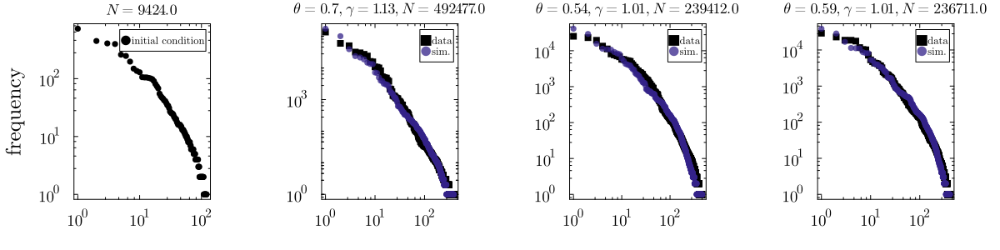

In [494]:
plot(ps1..., layout = (1,4), size = (1200,300), left_margin = 8mm, bottom_margin = 10mm, top_margin = 3mm, right_margin = 12mm)

# Index 2

Index choice below specifies the index of system we are dealing with.

In [495]:
ind_choice = 2;

In [496]:
data = gd_classes[ind_choice];

We need to get the size of each of these systems.

In [497]:
sizes = sum.([data[x][!,:count] for x in 1:length(data)]);
maximum(sizes)

130072.0

In [498]:
small_to_large = sortperm(sizes);

In [499]:
ic_sys = sort(data[small_to_large[2]][!,:count],rev=true);

In [500]:
# need to find the bounding value of p0
logxs = log10.(sum.([x[!,:count] for x in data]));
logys = log10.(length.([x[!,:count] for x in data]));
df = DataFrame(y = logys, x = logxs);
glm = lm(@formula(y ~ x), df);
a,b = coef(glm);
θ = 2+1/(b-1);
α = sum([k^θ for k in ic_sys])/(sum(ic_sys)^(1/(2-θ)));
p0_guess = α*b*10^a

18.666176081371837

Let's import the calibration results.

In [501]:
calib_results = CSV.read("/home/jamesh/GitHub/Ecological-Preferential-Attachment/Calibrations/calibration_results_p0_fixed2/eco-calib-$(ind_choice).csv", DataFrame)

Row,theta,gamma,fitness
,Float64,Float64,Float64
1,0.0924504,1.00613,6.92446
2,-0.367724,1.00248,6.98948
3,-0.241099,1.02641,6.77657
4,-0.537622,1.00918,7.38806
5,-0.11696,1.01718,7.6826
6,-0.0976402,0.979541,7.364
7,-0.447773,0.981394,5.45259
8,-0.317984,1.0089,5.14969
9,0.0576005,0.984839,5.70181


Take the size of the largest system, and simulate ecosystems of that size from this initial condition.

In [502]:
top10i = sortperm(sizes,rev=true)[1:10];

In [503]:
guess_sim = dsim.create_cell(calib_results[1,1],calib_results[1,2], p0_guess, convert(Int64,sizes[top10i[1]]), ic_sys, :pdf);

In [504]:
ps2 = []

Any[]

In [505]:
s1 = scatter(sort(data[argmin(sizes)][!,:count],rev=true), xaxis = :log, yaxis = :log, label = "initial condition", marker = :circle, color = :black)
plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, title = L"N=%$(sum(ic_sys))")
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12, ylabel = "frequency")
push!(ps2, s1)

1-element Vector{Any}:
 Plot{Plots.GRBackend() n=1}

In [506]:
gs2 = [dsim.create_cell(calib_results[i,1],calib_results[i,2], p0_guess, convert(Int64,sizes[top10i[i]]), ic_sys, :pdf) for i in 1:3]

3-element Vector{Vector{Float64}}:
 [7839.0, 5775.0, 5652.0, 5483.0, 4049.0, 3445.0, 2766.0, 2513.0, 2375.0, 2354.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
 [4481.0, 4282.0, 3741.0, 2974.0, 2433.0, 2388.0, 2096.0, 1908.0, 1889.0, 1716.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
 [5775.0, 4356.0, 4035.0, 3659.0, 3244.0, 3045.0, 2815.0, 2219.0, 2150.0, 1987.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]

In [507]:
for i in 1:3
    guess_sim = gs2[i]
    s = scatter(sort(data[top10i[i]][!,:count],rev=true), xaxis = :log, yaxis = :log, label = "data", marker = :rect, color = :black)
    scatter!(guess_sim, label = "sim.", grid = false, minorgrid = false, color = cpal_plot[2], alpha = 0.75)
    plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, 
    title = L"\theta = %$(round(calib_results[i,1], digits = 2)), \gamma = %$(round(calib_results[i,2], digits = 2)), N=%$(sum(data[top10i[i]][!,:count]))")
    plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12)
    push!(ps2,s)
end

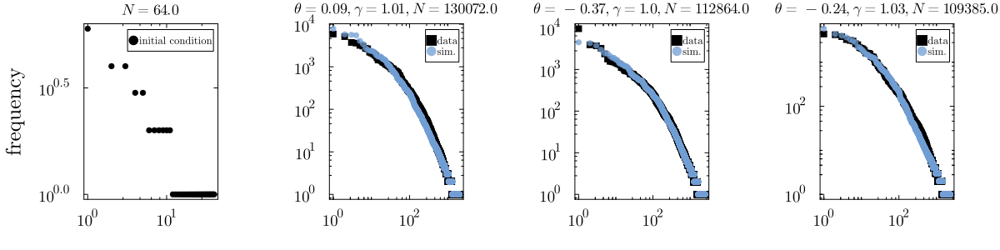

In [508]:
plot(ps2..., layout = (1,4), size = (1200,300), left_margin = 8mm, bottom_margin = 10mm, top_margin = 3mm, right_margin = 12mm)

# Index 3

Index choice below specifies the index of system we are dealing with.

In [509]:
ind_choice = 3;

In [510]:
data = gd_classes[ind_choice];

We need to get the size of each of these systems.

In [511]:
sizes = sum.([data[x][!,:count] for x in 1:length(data)]);
maximum(sizes)

561030.0

In [512]:
small_to_large = sortperm(sizes);

In [513]:
ic_sys = sort(data[small_to_large[2]][!,:count],rev=true);

In [514]:
# need to find the bounding value of p0
logxs = log10.(sum.([x[!,:count] for x in data]));
logys = log10.(length.([x[!,:count] for x in data]));
df = DataFrame(y = logys, x = logxs);
glm = lm(@formula(y ~ x), df);
a,b = coef(glm);
θ = 2+1/(b-1);
α = sum([k^θ for k in ic_sys])/(sum(ic_sys)^(1/(2-θ)));
p0_guess = α*b*10^a

132.4444810244406

Let's import the calibration results.

In [515]:
calib_results = CSV.read("/home/jamesh/GitHub/Ecological-Preferential-Attachment/Calibrations/calibration_results_p0_fixed2/eco-calib-$(ind_choice).csv", DataFrame)

Row,theta,gamma,fitness
,Float64,Float64,Float64
1,0.812961,1.13346,8.45692
2,0.751581,1.11364,13.305
3,0.683318,1.09956,13.1975
4,0.720985,1.10969,11.6918
5,0.700506,1.11233,13.0983
6,0.529608,1.08131,7.61163
7,0.738486,1.12591,10.2036
8,0.792956,1.13554,7.35457
9,0.663857,1.10513,6.56366


Take the size of the largest system, and simulate ecosystems of that size from this initial condition.

In [516]:
top10i = sortperm(sizes,rev=true)[1:10];

In [517]:
guess_sim = dsim.create_cell(calib_results[1,1],calib_results[1,2], p0_guess, convert(Int64,sizes[top10i[1]]), ic_sys, :pdf);

In [518]:
ps3 = []

Any[]

In [519]:
s1 = scatter(sort(data[argmin(sizes)][!,:count],rev=true), xaxis = :log, yaxis = :log, label = "initial condition", marker = :circle, color = :black)
plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, title = L"N=%$(sum(ic_sys))")
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12, ylabel = "frequency")
push!(ps3, s1)

1-element Vector{Any}:
 Plot{Plots.GRBackend() n=1}

In [520]:
gs3 = [dsim.create_cell(calib_results[i,1],calib_results[i,2], p0_guess, convert(Int64,sizes[top10i[i]]), ic_sys, :pdf) for i in 1:3]

3-element Vector{Vector{Float64}}:
 [190963.0, 128476.0, 106409.0, 16834.0, 4320.0, 3192.0, 2850.0, 2807.0, 2426.0, 2324.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
 [219798.0, 87022.0, 27785.0, 7876.0, 5926.0, 5872.0, 5718.0, 5698.0, 5149.0, 5040.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
 [63521.0, 49305.0, 41602.0, 19365.0, 14388.0, 8340.0, 8289.0, 6062.0, 5925.0, 5586.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]

In [521]:
for i in 1:3
    guess_sim = gs3[i];
    s = scatter(sort(data[top10i[i]][!,:count],rev=true), xaxis = :log, yaxis = :log, label = "data", marker = :rect, color = :black)
    scatter!(guess_sim, label = "sim.", grid = false, minorgrid = false, color = cpal_plot[3], alpha = 0.75)
    plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, 
    title = L"\theta = %$(round(calib_results[i,1], digits = 2)), \gamma = %$(round(calib_results[i,2], digits = 2)), N=%$(sum(data[top10i[i]][!,:count]))")
    plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12)
    push!(ps3,s)
end

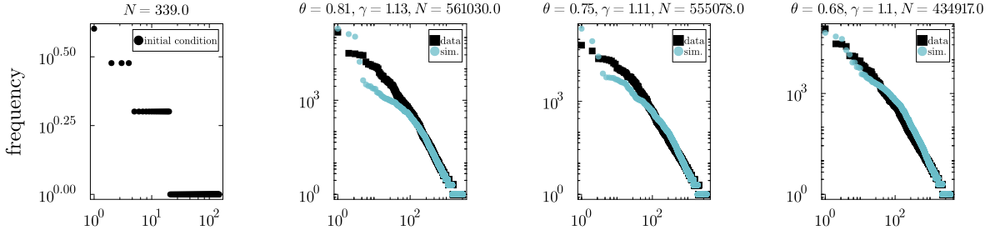

In [522]:
plot(ps3..., layout = (1,4), size = (1200,300), left_margin = 8mm, bottom_margin = 10mm, top_margin = 3mm, right_margin = 12mm)

# Index 4

Index choice below specifies the index of system we are dealing with.

In [523]:
ind_choice = 4;

In [524]:
data = gd_classes[ind_choice];

We need to get the size of each of these systems.

In [525]:
sizes = sum.([data[x][!,:count] for x in 1:length(data)]);
maximum(sizes)

13233.0

In [526]:
small_to_large = sortperm(sizes);

In [527]:
ic_sys = sort(data[small_to_large[2]][!,:count],rev=true);

In [528]:
# need to find the bounding value of p0
logxs = log10.(sum.([x[!,:count] for x in data]));
logys = log10.(length.([x[!,:count] for x in data]));
df = DataFrame(y = logys, x = logxs);
glm = lm(@formula(y ~ x), df);
a,b = coef(glm);
θ = 2+1/(b-1);
α = sum([k^θ for k in ic_sys])/(sum(ic_sys)^(1/(2-θ)));
p0_guess = α*b*10^a

6.519519153790294

Let's import the calibration results.

In [529]:
calib_results = CSV.read("/home/jamesh/GitHub/Ecological-Preferential-Attachment/Calibrations/calibration_results_p0_fixed2/eco-calib-$(ind_choice).csv", DataFrame)

Row,theta,gamma,fitness
,Float64,Float64,Float64
1,0.559432,1.21983,2.32169
2,0.552976,1.18592,1.82769
3,0.420694,1.16813,1.6482
4,0.378424,1.27099,2.01928
5,0.400471,1.1879,0.925094
6,0.547882,1.25441,1.86644
7,0.808893,1.40004,1.02967
8,0.679338,1.28704,1.15671
9,1.49596,1.49396,12.5273


Take the size of the largest system, and simulate ecosystems of that size from this initial condition.

In [530]:
top10i = sortperm(sizes,rev=true)[1:10];

In [531]:
guess_sim = dsim.create_cell(calib_results[1,1],calib_results[1,2], p0_guess, convert(Int64,sizes[top10i[1]]), ic_sys, :pdf);

In [532]:
ps4 = []

Any[]

In [533]:
s1 = scatter(sort(data[argmin(sizes)][!,:count],rev=true), xaxis = :log, yaxis = :log, label = "initial condition", marker = :circle, color = :black)
plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, title = L"N=%$(sum(ic_sys))")
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12, ylabel = "frequency")
push!(ps4, s1)

1-element Vector{Any}:
 Plot{Plots.GRBackend() n=1}

In [534]:
gs4 = [dsim.create_cell(calib_results[i,1],calib_results[i,2], p0_guess, convert(Int64,sizes[top10i[i]]), ic_sys, :pdf) for i in 1:3]

3-element Vector{Vector{Float64}}:
 [4960.0, 3565.0, 701.0, 387.0, 327.0, 308.0, 255.0, 234.0, 231.0, 212.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
 [2415.0, 1815.0, 935.0, 564.0, 311.0, 266.0, 262.0, 262.0, 247.0, 199.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
 [1203.0, 522.0, 475.0, 273.0, 239.0, 211.0, 184.0, 181.0, 170.0, 142.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]

In [535]:
for i in 1:3
    guess_sim = gs4[i];
    s = scatter(sort(data[top10i[i]][!,:count],rev=true), xaxis = :log, yaxis = :log, label = "data", marker = :rect, color = :black)
    scatter!(guess_sim, label = "sim.", grid = false, minorgrid = false, color = cpal_plot[4], alpha = 0.75)
    plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, 
    title = L"\theta = %$(round(calib_results[i,1], digits = 2)), \gamma = %$(round(calib_results[i,2], digits = 2)), N=%$(sum(data[top10i[i]][!,:count]))")
    plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12)
    push!(ps4,s)
end

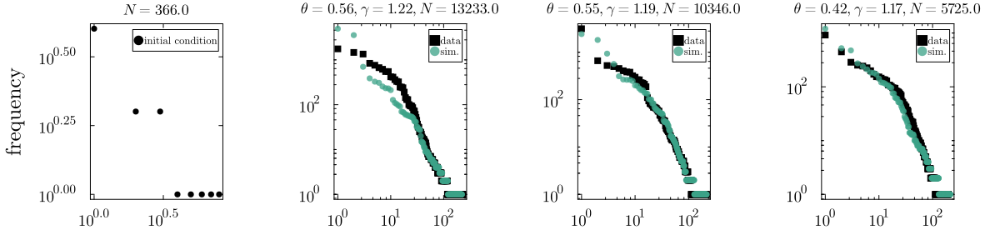

In [536]:
plot(ps4..., layout = (1,4), size = (1200,300), left_margin = 8mm, bottom_margin = 10mm, top_margin = 3mm, right_margin = 12mm)

# Index 5

Index choice below specifies the index of system we are dealing with.

In [537]:
ind_choice = 5;

In [538]:
data = gd_classes[ind_choice];

We need to get the size of each of these systems.

In [539]:
sizes = sum.([data[x][!,:count] for x in 1:length(data)]);
maximum(sizes)

41455.0

In [540]:
small_to_large = sortperm(sizes);

In [541]:
ic_sys = sort(data[small_to_large[2]][!,:count],rev=true);

In [542]:
# need to find the bounding value of p0
logxs = log10.(sum.([x[!,:count] for x in data]));
logys = log10.(length.([x[!,:count] for x in data]));
df = DataFrame(y = logys, x = logxs);
glm = lm(@formula(y ~ x), df);
a,b = coef(glm);
θ = 2+1/(b-1);
α = sum([k^θ for k in ic_sys])/(sum(ic_sys)^(1/(2-θ)));
p0_guess = α*b*10^a

24.63634429287424

Let's import the calibration results.

In [543]:
calib_results = CSV.read("/home/jamesh/GitHub/Ecological-Preferential-Attachment/Calibrations/calibration_results_p0_fixed2/eco-calib-$(ind_choice).csv", DataFrame)

Row,theta,gamma,fitness
,Float64,Float64,Float64
1,-0.0395186,1.08115,2.25316
2,-9.16463,0.93794,14.1867
3,0.284171,1.10868,4.80346
4,-0.247142,1.06863,2.47499
5,-0.893362,1.0326,2.47345
6,-0.13654,1.06993,3.52645
7,0.305682,1.08403,2.09734
8,-2.37923,1.01823,2.07429
9,-8.9216,0.948729,8.52914


Take the size of the largest system, and simulate ecosystems of that size from this initial condition.

In [544]:
top10i = sortperm(sizes,rev=true)[1:10];

In [545]:
guess_sim = dsim.create_cell(calib_results[1,1],calib_results[1,2], p0_guess, convert(Int64,sizes[top10i[1]]), ic_sys, :pdf);

In [546]:
ps5 = []

Any[]

In [547]:
s1 = scatter(sort(data[argmin(sizes)][!,:count],rev=true), xaxis = :log, yaxis = :log, label = "initial condition", marker = :circle, color = :black)
plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, title = L"N=%$(sum(ic_sys))")
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12, ylabel = "frequency")
push!(ps5, s1)

1-element Vector{Any}:
 Plot{Plots.GRBackend() n=1}

In [548]:
gs5 = [dsim.create_cell(calib_results[i,1],calib_results[i,2], p0_guess, convert(Int64,sizes[top10i[i]]), ic_sys, :pdf) for i in 1:3]

3-element Vector{Vector{Float64}}:
 [4037.0, 2947.0, 2617.0, 1985.0, 1961.0, 1960.0, 1622.0, 1410.0, 843.0, 691.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
 [1867.0, 1559.0, 1378.0, 1326.0, 1173.0, 1125.0, 821.0, 740.0, 553.0, 515.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
 [3751.0, 3212.0, 2468.0, 2463.0, 2342.0, 1832.0, 1310.0, 1151.0, 844.0, 790.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]

In [549]:
for i in 1:3
    guess_sim = gs5[i];
    s = scatter(sort(data[top10i[i]][!,:count],rev=true), xaxis = :log, yaxis = :log, label = "data", marker = :rect, color = :black)
    scatter!(guess_sim, label = "sim.", grid = false, minorgrid = false, color = cpal_plot[5], alpha = 0.75)
    plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, 
    title = L"\theta = %$(round(calib_results[i,1], digits = 2)), \gamma = %$(round(calib_results[i,2], digits = 2)), N=%$(sum(data[top10i[i]][!,:count]))")
    plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12)
    push!(ps5,s)
end

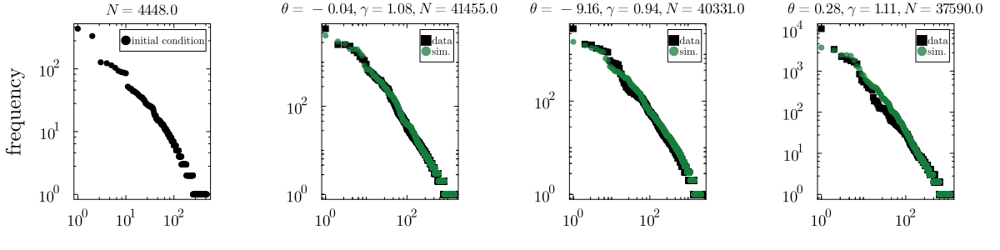

In [550]:
plot(ps5..., layout = (1,4), size = (1200,300), left_margin = 8mm, bottom_margin = 10mm, top_margin = 3mm, right_margin = 12mm)

# Index 6

Index choice below specifies the index of system we are dealing with.

In [665]:
ind_choice = 6;

In [666]:
data = gd_classes[ind_choice];

We need to get the size of each of these systems.

In [667]:
sizes = sum.([data[x][!,:count] for x in 1:length(data)]);
maximum(sizes)

59759.0

In [668]:
small_to_large = sortperm(sizes);

In [669]:
ic_sys = sort(data[small_to_large[2]][!,:count],rev=true);

In [670]:
# need to find the bounding value of p0
logxs = log10.(sum.([x[!,:count] for x in data]));
logys = log10.(length.([x[!,:count] for x in data]));
df = DataFrame(y = logys, x = logxs);
glm = lm(@formula(y ~ x), df);
a,b = coef(glm);
θ = 2+1/(b-1);
α = sum([k^θ for k in ic_sys])/(sum(ic_sys)^(1/(2-θ)));
p0_guess = α*b*10^a

1.829608314092498

Let's import the calibration results.

In [671]:
calib_results = CSV.read("/home/jamesh/GitHub/Ecological-Preferential-Attachment/Calibrations/calibration_results_p0_fixed2/eco-calib-$(ind_choice).csv", DataFrame)

Row,theta,gamma,fitness
,Float64,Float64,Float64
1,0.661997,1.02037,2.93821
2,0.704764,1.00746,2.35486
3,0.645872,0.987012,1.0958
4,0.706524,0.98226,2.22814
5,0.715997,1.03381,2.98273
6,0.645311,0.996235,1.73135
7,0.579885,0.954036,2.33085
8,0.643776,1.02685,1.33038
9,0.638408,1.00744,1.97999


Take the size of the largest system, and simulate ecosystems of that size from this initial condition.

In [672]:
top10i = sortperm(sizes,rev=true)[1:10];

In [673]:
guess_sim = dsim.create_cell(calib_results[1,1],calib_results[1,2], p0_guess, convert(Int64,sizes[top10i[1]]), ic_sys, :pdf);

In [674]:
ps6 = []

Any[]

In [675]:
s1 = scatter(sort(data[argmin(sizes)][!,:count],rev=true), xaxis = :log, yaxis = :log, label = "initial condition", marker = :circle, color = :black)
plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, title = L"N=%$(sum(ic_sys))")
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12, ylabel = "frequency", xlabel = "rank")
push!(ps6, s1)

1-element Vector{Any}:
 Plot{Plots.GRBackend() n=1}

In [562]:
gs6 = [dsim.create_cell(calib_results[i,1],calib_results[i,2], p0_guess, convert(Int64,sizes[top10i[i]]), ic_sys, :pdf) for i in 1:3]

3-element Vector{Vector{Float64}}:
 [13257.0, 10101.0, 9562.0, 8767.0, 3821.0, 3379.0, 2664.0, 2590.0, 1346.0, 669.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
 [12371.0, 9577.0, 9164.0, 8303.0, 3277.0, 3161.0, 2534.0, 2448.0, 1335.0, 745.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
 [10591.0, 8308.0, 8199.0, 7370.0, 3235.0, 3214.0, 2480.0, 2390.0, 1658.0, 685.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]

In [676]:
for i in 1:3
    guess_sim = gs6[i];
    s = scatter(sort(data[top10i[i]][!,:count],rev=true), xaxis = :log, yaxis = :log, label = "data", marker = :rect, color = :black)
    scatter!(guess_sim, label = "sim.", grid = false, minorgrid = false, color = cpal_plot[6], alpha = 0.75)
    plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, 
    title = L"\theta = %$(round(calib_results[i,1], digits = 2)), \gamma = %$(round(calib_results[i,2], digits = 2)), N=%$(sum(data[top10i[i]][!,:count]))")
    plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12, xlabel = "rank")
    push!(ps6,s)
end

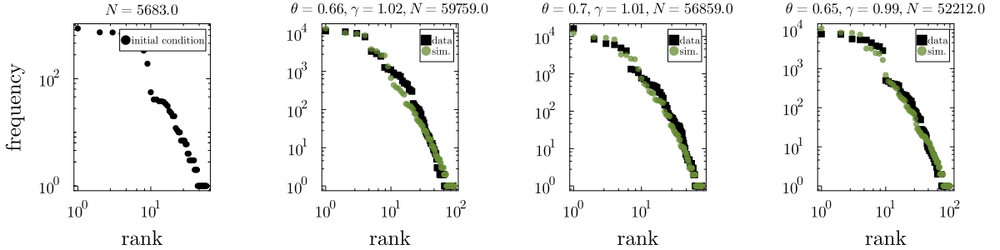

In [677]:
plot(ps6..., layout = (1,4), size = (1200,300), left_margin = 8mm, bottom_margin = 10mm, top_margin = 3mm, right_margin = 12mm)

# Index 8

Index choice below specifies the index of system we are dealing with.

In [565]:
ind_choice = 8;

In [566]:
data = gd_classes[ind_choice];

We need to get the size of each of these systems.

In [567]:
sizes = sum.([data[x][!,:count] for x in 1:length(data)]);
maximum(sizes)

91953.0

In [568]:
small_to_large = sortperm(sizes);

In [569]:
ic_sys = sort(data[small_to_large[2]][!,:count],rev=true);

In [570]:
# need to find the bounding value of p0
logxs = log10.(sum.([x[!,:count] for x in data]));
logys = log10.(length.([x[!,:count] for x in data]));
df = DataFrame(y = logys, x = logxs);
glm = lm(@formula(y ~ x), df);
a,b = coef(glm);
θ = 2+1/(b-1);
α = sum([k^θ for k in ic_sys])/(sum(ic_sys)^(1/(2-θ)));
p0_guess = α*b*10^a

6.166505204048891

Let's import the calibration results.

In [571]:
calib_results = CSV.read("/home/jamesh/GitHub/Ecological-Preferential-Attachment/Calibrations/calibration_results_p0_fixed2/eco-calib-$(ind_choice).csv", DataFrame)

Row,theta,gamma,fitness
,Float64,Float64,Float64
1,0.482041,0.963974,5.91972
2,0.54143,0.99422,3.15644
3,0.540029,1.00323,2.54557
4,0.465995,1.01402,2.93203
5,0.44769,0.986365,2.10232
6,0.469691,0.976503,3.55462
7,0.434847,0.966192,2.77025
8,0.328838,0.97269,1.92308
9,0.361542,0.949238,2.89642


Take the size of the largest system, and simulate ecosystems of that size from this initial condition.

In [572]:
top10i = sortperm(sizes,rev=true)[1:10];

In [573]:
guess_sim = dsim.create_cell(calib_results[1,1],calib_results[1,2], p0_guess, convert(Int64,sizes[top10i[1]]), ic_sys, :pdf);

In [574]:
ps8 = []

Any[]

In [575]:
s1 = scatter(sort(data[argmin(sizes)][!,:count],rev=true), xaxis = :log, yaxis = :log, label = "initial condition", marker = :circle, color = :black)
plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, title = L"N=%$(sum(ic_sys))")
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12, ylabel = "frequency")
push!(ps8, s1)

1-element Vector{Any}:
 Plot{Plots.GRBackend() n=1}

In [576]:
gs8 = [dsim.create_cell(calib_results[i,1],calib_results[i,2], p0_guess, convert(Int64,sizes[top10i[i]]), ic_sys, :pdf) for i in 1:3]

3-element Vector{Vector{Float64}}:
 [12702.0, 5713.0, 5453.0, 5277.0, 4911.0, 3386.0, 2340.0, 2064.0, 2028.0, 2014.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
 [15980.0, 5529.0, 5020.0, 4473.0, 2996.0, 2810.0, 2743.0, 2171.0, 2071.0, 1963.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
 [13493.0, 6863.0, 5640.0, 4630.0, 3873.0, 2539.0, 2249.0, 2246.0, 2053.0, 1656.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]

In [577]:
for i in 1:3
    guess_sim = gs8[i];
    s = scatter(sort(data[top10i[i]][!,:count],rev=true), xaxis = :log, yaxis = :log, label = "data", marker = :rect, color = :black)
    scatter!(guess_sim, label = "sim.", grid = false, minorgrid = false, color = cpal_plot[7], alpha = 0.75)
    plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, 
    title = L"\theta = %$(round(calib_results[i,1], digits = 2)), \gamma = %$(round(calib_results[i,2], digits = 2)), N=%$(sum(data[top10i[i]][!,:count]))")
    plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12)
    push!(ps8,s)
end

In [651]:
plot(ps8..., layout = (1,4), size = (1200,300), left_margin = 8mm, bottom_margin = 10mm, top_margin = 3mm, right_margin = 12mm);

# Index 9

Index choice below specifies the index of system we are dealing with.

In [579]:
ind_choice = 9;

In [580]:
data = gd_classes[ind_choice];

We need to get the size of each of these systems.

In [581]:
sizes = sum.([data[x][!,:count] for x in 1:length(data)]);
maximum(sizes)

616671.0

In [582]:
small_to_large = sortperm(sizes);

In [583]:
ic_sys = sort(data[small_to_large[2]][!,:count],rev=true);

In [584]:
# need to find the bounding value of p0
logxs = log10.(sum.([x[!,:count] for x in data]));
logys = log10.(length.([x[!,:count] for x in data]));
df = DataFrame(y = logys, x = logxs);
glm = lm(@formula(y ~ x), df);
a,b = coef(glm);
θ = 2+1/(b-1);
α = sum([k^θ for k in ic_sys])/(sum(ic_sys)^(1/(2-θ)));
p0_guess = α*b*10^a

36.949408927933675

Let's import the calibration results.

In [585]:
calib_results = CSV.read("/home/jamesh/GitHub/Ecological-Preferential-Attachment/Calibrations/calibration_results_p0_fixed2/eco-calib-$(ind_choice).csv", DataFrame)

Row,theta,gamma,fitness
,Float64,Float64,Float64
1,0.589999,1.0508,3.73007
2,0.582326,1.05642,4.70687
3,0.723492,1.12957,5.05266
4,0.739314,1.12549,4.39562
5,0.739574,1.10791,3.02291
6,0.596537,1.05501,8.57043
7,0.633908,1.07903,6.00349
8,0.604236,1.05836,5.18661
9,0.530607,1.0482,3.32711


Take the size of the largest system, and simulate ecosystems of that size from this initial condition.

In [586]:
top10i = sortperm(sizes,rev=true)[1:10];

In [587]:
guess_sim = dsim.create_cell(calib_results[1,1],calib_results[1,2], p0_guess, convert(Int64,sizes[top10i[1]]), ic_sys, :pdf);

In [588]:
ps9 = []

Any[]

In [589]:
s1 = scatter(sort(data[argmin(sizes)][!,:count],rev=true), xaxis = :log, yaxis = :log, label = "initial condition", marker = :circle, color = :black)
plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, title = L"N=%$(sum(ic_sys))")
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12, ylabel = "frequency")
push!(ps9, s1)

1-element Vector{Any}:
 Plot{Plots.GRBackend() n=1}

In [590]:
gs9 = [dsim.create_cell(calib_results[i,1],calib_results[i,2], p0_guess, convert(Int64,sizes[top10i[i]]), ic_sys, :pdf) for i in 1:3]

3-element Vector{Vector{Float64}}:
 [153367.0, 79192.0, 48717.0, 23420.0, 20616.0, 12796.0, 11683.0, 10661.0, 9174.0, 9172.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
 [145975.0, 78673.0, 44153.0, 20737.0, 19588.0, 11629.0, 10983.0, 9782.0, 8306.0, 8233.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
 [168699.0, 77286.0, 40696.0, 16710.0, 14593.0, 7762.0, 7481.0, 6714.0, 6347.0, 5725.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]

In [591]:
for i in 1:3
    guess_sim = gs9[i];
    s = scatter(sort(data[top10i[i]][!,:count],rev=true), xaxis = :log, yaxis = :log, label = "data", marker = :rect, color = :black)
    scatter!(guess_sim, label = "sim.", grid = false, minorgrid = false, color = cpal_plot[8], alpha = 0.75)
    plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, 
    title = L"\theta = %$(round(calib_results[i,1], digits = 2)), \gamma = %$(round(calib_results[i,2], digits = 2)), N=%$(sum(data[top10i[i]][!,:count]))")
    plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12)
    push!(ps9,s)
end

In [650]:
plot(ps9..., layout = (1,4), size = (1200,300), left_margin = 8mm, bottom_margin = 10mm, top_margin = 3mm, right_margin = 12mm);

# Index 12

Index choice below specifies the index of system we are dealing with.

In [593]:
ind_choice = 12;

In [594]:
data = gd_classes[ind_choice];

We need to get the size of each of these systems.

In [595]:
sizes = sum.([data[x][!,:count] for x in 1:length(data)]);
maximum(sizes)

205465.0

In [596]:
small_to_large = sortperm(sizes);

In [597]:
ic_sys = sort(data[small_to_large[2]][!,:count],rev=true);

In [598]:
# need to find the bounding value of p0
logxs = log10.(sum.([x[!,:count] for x in data]));
logys = log10.(length.([x[!,:count] for x in data]));
df = DataFrame(y = logys, x = logxs);
glm = lm(@formula(y ~ x), df);
a,b = coef(glm);
θ = 2+1/(b-1);
α = sum([k^θ for k in ic_sys])/(sum(ic_sys)^(1/(2-θ)));
p0_guess = α*b*10^a

14.704079665851605

Let's import the calibration results.

In [599]:
calib_results = CSV.read("/home/jamesh/GitHub/Ecological-Preferential-Attachment/Calibrations/calibration_results_p0_fixed2/eco-calib-$(ind_choice).csv", DataFrame)

Row,theta,gamma,fitness
,Float64,Float64,Float64
1,0.0959447,1.07465,4.7334
2,-7.56647,0.93295,24.5357
3,0.19681,1.0512,6.54301
4,0.376414,1.07874,6.20984
5,0.434455,1.14572,6.26094
6,0.144514,1.05677,6.4174
7,0.259881,1.09473,7.08671
8,0.190514,1.00957,7.52686
9,0.341198,1.11199,6.11035


Take the size of the largest system, and simulate ecosystems of that size from this initial condition.

In [600]:
top10i = sortperm(sizes,rev=true)[1:10];

In [601]:
guess_sim = dsim.create_cell(calib_results[1,1],calib_results[1,2], p0_guess, convert(Int64,sizes[top10i[1]]), ic_sys, :pdf);

In [602]:
ps12 = []

Any[]

In [603]:
s1 = scatter(sort(data[argmin(sizes)][!,:count],rev=true), xaxis = :log, yaxis = :log, label = "initial condition", marker = :circle, color = :black)
plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, title = L"N=%$(sum(ic_sys))")
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12, ylabel = "frequency")
push!(ps12, s1)

1-element Vector{Any}:
 Plot{Plots.GRBackend() n=1}

In [604]:
gs12 = [dsim.create_cell(calib_results[i,1],calib_results[i,2], p0_guess, convert(Int64,sizes[top10i[i]]), ic_sys, :pdf) for i in 1:3]

3-element Vector{Vector{Float64}}:
 [20979.0, 17906.0, 12462.0, 10955.0, 10303.0, 9245.0, 6852.0, 5606.0, 5143.0, 5044.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
 [11702.0, 10127.0, 7497.0, 7095.0, 6702.0, 5957.0, 4898.0, 4149.0, 3983.0, 3924.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
 [12168.0, 10460.0, 7365.0, 6916.0, 6221.0, 5556.0, 4031.0, 3815.0, 3608.0, 3267.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]

In [605]:
for i in 1:3
    guess_sim = gs12[i];
    s = scatter(sort(data[top10i[i]][!,:count],rev=true), xaxis = :log, yaxis = :log, label = "data", marker = :rect, color = :black)
    scatter!(guess_sim, label = "sim.", grid = false, minorgrid = false, color = cpal_plot[9], alpha = 0.75)
    plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, 
    title = L"\theta = %$(round(calib_results[i,1], digits = 2)), \gamma = %$(round(calib_results[i,2], digits = 2)), N=%$(sum(data[top10i[i]][!,:count]))")
    plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12)
    push!(ps12,s)
end

In [649]:
plot(ps12..., layout = (1,4), size = (1200,300), left_margin = 8mm, bottom_margin = 10mm, top_margin = 3mm, right_margin = 12mm);

# Index 13

Index choice below specifies the index of system we are dealing with.

In [607]:
ind_choice = 13;

In [608]:
data = gd_classes[ind_choice];

We need to get the size of each of these systems.

In [609]:
sizes = sum.([data[x][!,:count] for x in 1:length(data)]);
maximum(sizes)

3324.0

In [610]:
small_to_large = sortperm(sizes);

In [611]:
ic_sys = sort(data[small_to_large[2]][!,:count],rev=true);

In [612]:
# need to find the bounding value of p0
logxs = log10.(sum.([x[!,:count] for x in data]));
logys = log10.(length.([x[!,:count] for x in data]));
df = DataFrame(y = logys, x = logxs);
glm = lm(@formula(y ~ x), df);
a,b = coef(glm);
θ = 2+1/(b-1);
α = sum([k^θ for k in ic_sys])/(sum(ic_sys)^(1/(2-θ)));
p0_guess = α*b*10^a

72.2880905754131

Let's import the calibration results.

In [613]:
calib_results = CSV.read("/home/jamesh/GitHub/Ecological-Preferential-Attachment/Calibrations/calibration_results_p0_fixed2/eco-calib-$(ind_choice).csv", DataFrame)

Row,theta,gamma,fitness
,Float64,Float64,Float64
1,-9.24904,1.22877,2.71159
2,-2.0609,1.21869,1.14574
3,-9.93465,1.20581,3.7354
4,-3.28113,1.21921,0.943988
5,-7.94649,1.17448,1.08234
6,-1.42477,1.26189,0.964386
7,-9.63609,1.24506,2.38045
8,0.400026,1.2852,0.726617
9,-1.60624,1.20736,1.1988


Take the size of the largest system, and simulate ecosystems of that size from this initial condition.

In [614]:
top10i = sortperm(sizes,rev=true)[1:10];

In [615]:
guess_sim = dsim.create_cell(calib_results[1,1],calib_results[1,2], p0_guess, convert(Int64,sizes[top10i[1]]), ic_sys, :pdf);

In [616]:
ps13 = []

Any[]

In [617]:
s1 = scatter(sort(data[argmin(sizes)][!,:count],rev=true), xaxis = :log, yaxis = :log, label = "initial condition", marker = :circle, color = :black)
plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, title = L"N=%$(sum(ic_sys))")
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12, ylabel = "frequency")
push!(ps13, s1)

1-element Vector{Any}:
 Plot{Plots.GRBackend() n=1}

In [618]:
gs13 = [dsim.create_cell(calib_results[i,1],calib_results[i,2], p0_guess, convert(Int64,sizes[top10i[i]]), ic_sys, :pdf) for i in 1:3]

3-element Vector{Vector{Float64}}:
 [340.0, 216.0, 118.0, 114.0, 50.0, 38.0, 36.0, 33.0, 31.0, 29.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
 [205.0, 147.0, 70.0, 61.0, 57.0, 56.0, 51.0, 49.0, 44.0, 41.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
 [90.0, 70.0, 51.0, 48.0, 43.0, 36.0, 36.0, 31.0, 28.0, 26.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]

In [619]:
for i in 1:3
    guess_sim = gs13[i];
    s = scatter(sort(data[top10i[i]][!,:count],rev=true), xaxis = :log, yaxis = :log, label = "data", marker = :rect, color = :black)
    scatter!(guess_sim, label = "sim.", grid = false, minorgrid = false, color = cpal_plot[10], alpha = 0.75)
    plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, 
    title = L"\theta = %$(round(calib_results[i,1], digits = 2)), \gamma = %$(round(calib_results[i,2], digits = 2)), N=%$(sum(data[top10i[i]][!,:count]))")
    plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12)
    push!(ps13,s)
end

In [648]:
plot(ps13..., layout = (1,4), size = (1200,300), left_margin = 8mm, bottom_margin = 10mm, top_margin = 3mm, right_margin = 12mm);

# Index 14

Index choice below specifies the index of system we are dealing with.

In [621]:
ind_choice = 14;

In [622]:
data = gd_classes[ind_choice];

We need to get the size of each of these systems.

In [623]:
sizes = sum.([data[x][!,:count] for x in 1:length(data)]);
maximum(sizes)

481258.0

In [624]:
small_to_large = sortperm(sizes);

In [625]:
ic_sys = sort(data[small_to_large[2]][!,:count],rev=true);

In [626]:
# need to find the bounding value of p0
logxs = log10.(sum.([x[!,:count] for x in data]));
logys = log10.(length.([x[!,:count] for x in data]));
df = DataFrame(y = logys, x = logxs);
glm = lm(@formula(y ~ x), df);
a,b = coef(glm);
θ = 2+1/(b-1);
α = sum([k^θ for k in ic_sys])/(sum(ic_sys)^(1/(2-θ)));
p0_guess = α*b*10^a

99.03122020250318

Let's import the calibration results.

In [627]:
calib_results = CSV.read("/home/jamesh/GitHub/Ecological-Preferential-Attachment/Calibrations/calibration_results_p0_fixed2/eco-calib-$(ind_choice).csv", DataFrame)

Row,theta,gamma,fitness
,Float64,Float64,Float64
1,0.302937,1.02715,12.1845
2,0.074925,1.02336,11.0701
3,0.0014785,0.999864,14.3287
4,0.22086,1.01571,11.0865
5,0.0257418,0.988227,11.5266
6,0.116499,1.00541,9.66804
7,0.109729,1.01686,12.9755
8,0.155523,1.0088,15.2892
9,0.286567,1.02566,10.8602


Take the size of the largest system, and simulate ecosystems of that size from this initial condition.

In [628]:
top10i = sortperm(sizes,rev=true)[1:10];

In [629]:
guess_sim = dsim.create_cell(calib_results[1,1],calib_results[1,2], p0_guess, convert(Int64,sizes[top10i[1]]), ic_sys, :pdf);

In [630]:
ps14 = []

Any[]

In [631]:
s1 = scatter(sort(data[argmin(sizes)][!,:count],rev=true), xaxis = :log, yaxis = :log, label = "initial condition", marker = :circle, color = :black)
plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, title = L"N=%$(sum(ic_sys))")
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12, xlabel = "rank", ylabel = "frequency")
push!(ps14, s1)

1-element Vector{Any}:
 Plot{Plots.GRBackend() n=1}

In [632]:
gs14 = [dsim.create_cell(calib_results[i,1],calib_results[i,2], p0_guess, convert(Int64,sizes[top10i[i]]), ic_sys, :pdf) for i in 1:3]

3-element Vector{Vector{Float64}}:
 [61430.0, 29313.0, 25746.0, 25077.0, 24602.0, 10015.0, 8533.0, 8072.0, 7897.0, 7472.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
 [46592.0, 22953.0, 21236.0, 19793.0, 18449.0, 8707.0, 7107.0, 6645.0, 5797.0, 5601.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
 [34066.0, 18727.0, 17105.0, 15573.0, 15473.0, 6310.0, 6037.0, 5480.0, 5409.0, 5335.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]

In [633]:
for i in 1:3
    guess_sim = gs14[i];
    s = scatter(sort(data[top10i[i]][!,:count],rev=true), xaxis = :log, yaxis = :log, label = "data", marker = :rect, color = :black)
    scatter!(guess_sim, label = "sim.", xlabel = "rank", grid = false, minorgrid = false, color = cpal_plot[11], alpha = 0.75)
    plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, 
    title = L"\theta = %$(round(calib_results[i,1], digits = 2)), \gamma = %$(round(calib_results[i,2], digits = 2)), N=%$(sum(data[top10i[i]][!,:count]))")
    plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12)
    push!(ps14,s)
end

In [647]:
plot(ps14..., layout = (1,4), size = (1200,300), left_margin = 8mm, bottom_margin = 10mm, top_margin = 3mm, right_margin = 12mm);

# All plots together

In [635]:
all_p = vcat(ps1,ps2,ps3,ps4,ps5,ps6,ps8,ps9,ps12,ps13,ps14)

44-element Vector{Any}:
 Plot{Plots.GRBackend() n=1}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=1}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=1}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=1}
 ⋮
 Plot{Plots.GRBackend() n=1}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=1}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=1}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=2}

In [646]:
plot(all_p..., layout = (11,4), size = (1300,3000), left_margin = 25mm, bottom_margin = 0mm, top_margin = 0mm, right_margin = 0mm);
# savefig("./calibration-plots-11x4.pdf")

In [679]:
first_6_p = vcat(ps1,ps2,ps3,ps4,ps5,ps6)
final_5_p = vcat(ps8,ps9,ps12,ps13,ps14)

20-element Vector{Any}:
 Plot{Plots.GRBackend() n=1}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=1}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=1}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=1}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=1}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=2}

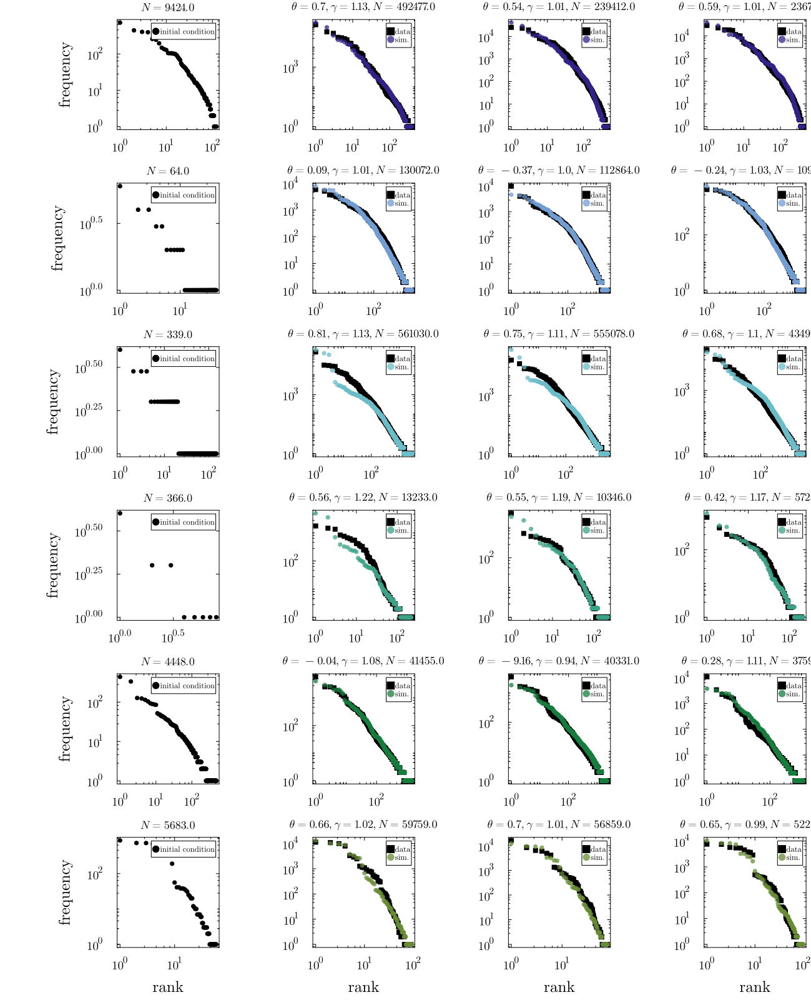

In [683]:
plot(first_6_p..., layout = (6,4), size = (1300,1600), left_margin = 25mm, bottom_margin = 0mm, top_margin = 0mm, right_margin = 0mm)
# savefig("rf-plots-1-6.pdf")

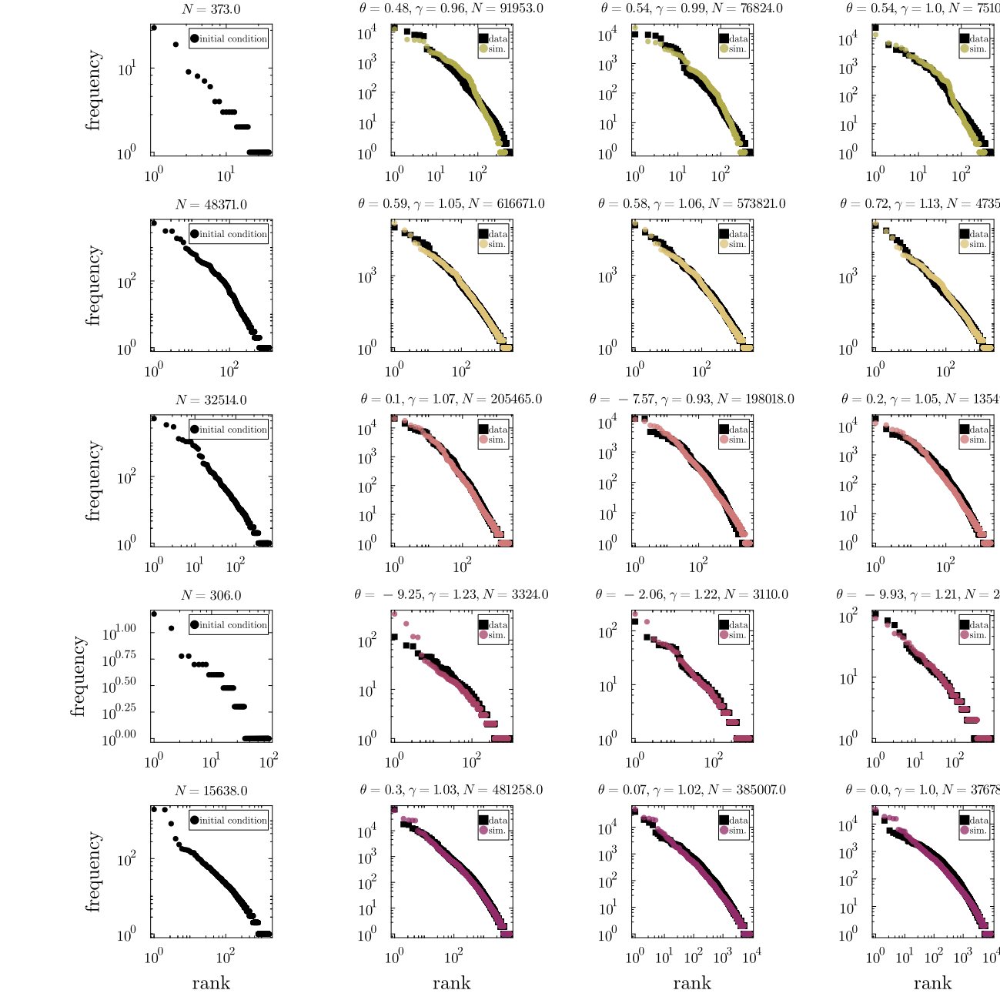

In [684]:
plot(final_5_p..., layout = (5,4), size = (1300,1300), left_margin = 25mm, bottom_margin = 0mm, top_margin = 0mm, right_margin = 0mm)
# savefig("rf-plots-last-5.pdf")